# LIBRAIRIE

In [69]:
import numpy as np
np.set_printoptions(threshold=10000, suppress=True)
import pandas as pd
import warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, accuracy_score, precision_score, recall_score
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler

from sklearn.decomposition import PCA

#import import_ipynb
#import notebook

In [70]:
import sys
import io
from contextlib import redirect_stdout, redirect_stderr

# Supprimer l'affichage pendant l'import
f = io.StringIO()
with redirect_stdout(f), redirect_stderr(f):
    import import_ipynb
    import notebook

# Maintenant vous avez accès aux variables sans l'affichage
print("Import réussi !")

Import réussi !


# CHARGEMENT DES DONNEES

In [71]:
df2 = pd.read_csv('credit.data', header=None, sep='\s+', na_values='?')

In [72]:
# Afficher les premières lignes pour inspection
print("Premières lignes du dataset")
print(df2.head())
print("\n")
print(f"Type deu dataset : {type(df2)}") # on voit bien quil est en dataframe

Premières lignes du dataset
  0      1      2  3  4  5  6     7  8  9   10 11 12     13   14 15
0  b  30.83  0.000  u  g  w  v  1.25  t  t   1  f  g  202.0    0  +
1  a  58.67  4.460  u  g  q  h  3.04  t  t   6  f  g   43.0  560  +
2  a  24.50  0.500  u  g  q  h  1.50  t  f   0  f  g  280.0  824  +
3  b  27.83  1.540  u  g  w  v  3.75  t  t   5  t  g  100.0    3  +
4  b  20.17  5.625  u  g  w  v  1.71  t  f   0  f  s  120.0    0  +


Type deu dataset : <class 'pandas.core.frame.DataFrame'>


# TRANSFORMATION EN NUMPY

In [73]:
# 2. Transformation en numpy array
df2_numpy = df2.values
print(f" Transformation en numpu array\n {df2_numpy}")
print(f"Type de data_array : {type(df2_numpy)}") # transformation reussi en numpy array

 Transformation en numpu array
 [['b' 30.83 0.0 ... 202.0 0 '+']
 ['a' 58.67 4.46 ... 43.0 560 '+']
 ['a' 24.5 0.5 ... 280.0 824 '+']
 ...
 ['a' 25.25 13.5 ... 200.0 1 '-']
 ['b' 17.92 0.205 ... 280.0 750 '-']
 ['b' 35.0 3.375 ... 0.0 0 '-']]
Type de data_array : <class 'numpy.ndarray'>


# SEPARATION DES X ET Y

In [74]:
# Séparation des caractéristiques (X) et de la variable cible (y)
X = df2_numpy[:, :-1]  # Toutes les colonnes sauf la dernière
y = df2_numpy[:, -1]   # Dernière colonne (status)

# DETAIL DU DATASET

In [76]:
print(f"Shape de X (caractéristiques): {X.shape}")
print(f"Shape de y (target): {y.shape}")
print("\nPremières lignes de X:")
print(X[:3])
print("\nPremières valeurs de y:")
print(y[:3])

Shape de X (caractéristiques): (688, 15)
Shape de y (target): (688,)

Premières lignes de X:
[['b' 30.83 0.0 'u' 'g' 'w' 'v' 1.25 't' 't' 1 'f' 'g' 202.0 0]
 ['a' 58.67 4.46 'u' 'g' 'q' 'h' 3.04 't' 't' 6 'f' 'g' 43.0 560]
 ['a' 24.5 0.5 'u' 'g' 'q' 'h' 1.5 't' 'f' 0 'f' 'g' 280.0 824]]

Premières valeurs de y:
['+' '+' '+']


## SUPPRIMER LES NAN

In [77]:
# Colonnes avec des valeurs numériques : 1, 2, 7, 10, 13, 14
numerical_indices = [1, 2, 7, 10, 13, 14]

# Création du sous-ensemble avec seulement les variables numériques
X_numerical = X[:, numerical_indices]

# Remplacer '?' par nan et convertir en float
X_numerical = np.where(X_numerical == '?', np.nan, X_numerical)
X_numerical = X_numerical.astype(float)

In [78]:
print(f"Shape du sous-ensemble numérique: {X_numerical.shape}")
print(f"Type: {X_numerical.dtype}")
print("\nPremières lignes:")
print(X_numerical[:5])

Shape du sous-ensemble numérique: (688, 6)
Type: float64

Premières lignes:
[[ 30.83    0.      1.25    1.    202.      0.   ]
 [ 58.67    4.46    3.04    6.     43.    560.   ]
 [ 24.5     0.5     1.5     0.    280.    824.   ]
 [ 27.83    1.54    3.75    5.    100.      3.   ]
 [ 20.17    5.625   1.71    0.    120.      0.   ]]


In [79]:
# Supprimer les individus avec des valeurs manquantes (nan)
mask = ~np.any(np.isnan(X_numerical), axis=1)
X_clean = X_numerical[mask]
y_clean = y[mask]

In [80]:
print(f"Shape après suppression des NaN - X_clean: {X_clean.shape}")
print(f"Shape après suppression des NaN - y_clean: {y_clean.shape}")

Shape après suppression des NaN - X_clean: (666, 6)
Shape après suppression des NaN - y_clean: (666,)


In [81]:
# Analyser les propriétés
print(f"\nTaille de l'échantillon: {X_clean.shape[0]} instances")
print(f"Nombre de caractéristiques numériques: {X_clean.shape[1]}")


Taille de l'échantillon: 666 instances
Nombre de caractéristiques numériques: 6


## CLASSE NEGATIVE/POSITIVE

In [86]:
# Compter les exemples positifs et négatifs
unique, counts = np.unique(y_clean, return_counts=True)
print(f"\nDistribution des classes: {dict(zip(unique, counts))}")


Distribution des classes: {'+': np.int64(299), '-': np.int64(367)}


In [87]:
# Binariser la target (+ en 1 et - en 0)
y_binary = np.where(y_clean == '+', 1, 0)

In [88]:
print(f"\nAprès binarisation {dict(zip(['0 (-)', '1 (+)'], np.bincount(y_binary)))}")


Après binarisation {'0 (-)': np.int64(367), '1 (+)': np.int64(299)}


In [89]:
print(X_clean[:3])
print(y_clean[:3])
print(y_binary[:3])

[[ 30.83   0.     1.25   1.   202.     0.  ]
 [ 58.67   4.46   3.04   6.    43.   560.  ]
 [ 24.5    0.5    1.5    0.   280.   824.  ]]
['+' '+' '+']
[1 1 1]


# COMPARAISON DES ALGOS

### DIVISION TRAIN TEST 

In [90]:
# Division train-test pour utiliser best_model, best_model_name, all_results = notebook.run_classifiers_train_test

X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_binary, test_size=0.3, random_state=42, stratify=y_binary
)

In [91]:
print(f"\nDivision train-test:")
print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")


Division train-test:
X_train: (466, 6), y_train: (466,)
X_test: (200, 6), y_test: (200,)


### LES ALGOS

In [92]:
print("Algorithmes:", list(notebook.algorithms.keys()))

Algorithmes: ['CART', 'KNN-5', 'MLP']


Début de l'apprentissage...
=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.6750
Precision:   0.6316
Recall:      0.6667
Score final: 0.6708 (Accuracy + Recall)/2
AUC:         0.6742

 KNN-5
------------------------------
Accuracy:    0.6850
Precision:   0.6901
Recall:      0.5444
Score final: 0.6147 (Accuracy + Recall)/2
AUC:         0.7284

 MLP
------------------------------
Accuracy:    0.7200
Precision:   0.7179
Recall:      0.6222
Score final: 0.6711 (Accuracy + Recall)/2
AUC:         0.7460

COMPARAISON DES MODÈLES
CART       : 0.6708
KNN-5      : 0.6147
MLP        : 0.6711

 MEILLEUR MODÈLE: MLP avec un score de 0.6711

VISUALISATIONS

Courbes ROC :


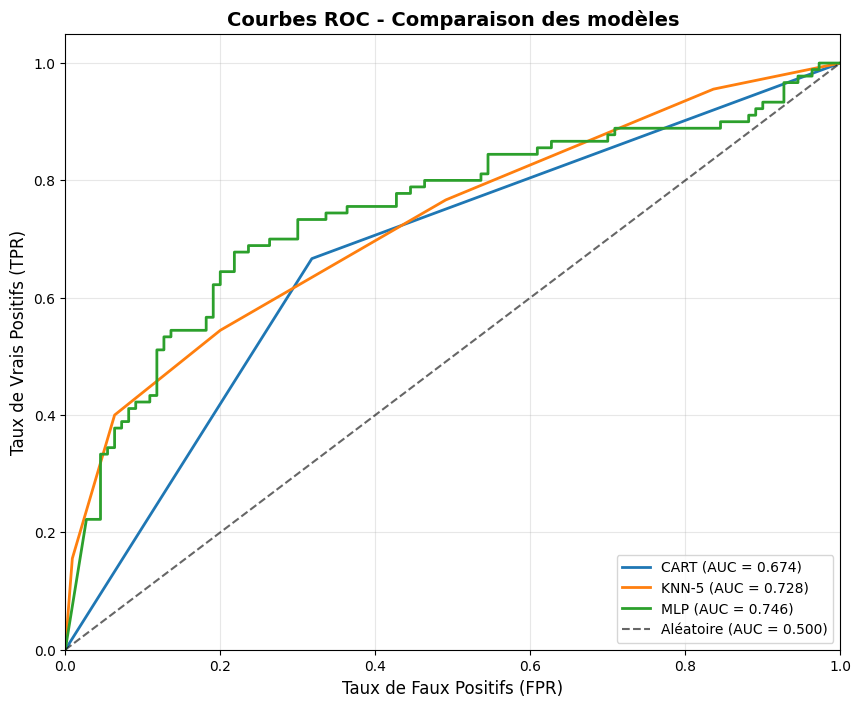


Matrices de confusion :


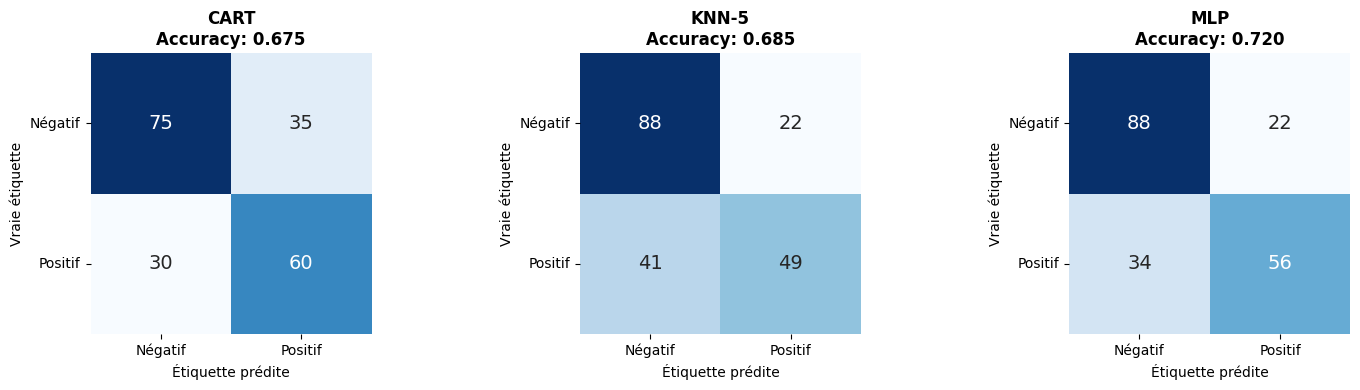


 MEILLEUR MODÈLE SÉLECTIONNÉ: MLP


In [93]:
print("Début de l'apprentissage...")
best_model, best_model_name, all_results = notebook.run_classifiers_train_test(
    X_train, X_test, y_train, y_test
)

# Affichage des visualisations
print("\n" + "=" * 60)
print("VISUALISATIONS")
print("=" * 60)

# Courbes ROC
print("\nCourbes ROC :")
notebook.plot_roc_curves(all_results)

# Matrices de confusion
print("\nMatrices de confusion :")
notebook.plot_confusion_matrices(all_results)

print(f"\n MEILLEUR MODÈLE SÉLECTIONNÉ: {best_model_name}")

# NORMALISATION (StandardScaler/MinMaxScaler)


In [94]:
# Normalisation des données
print("NORMALISATION DES DONNÉES")
X_train_std, X_test_std, scaler_std = notebook.normalize_data(X_train, X_test, method='standard')

print("Données normalisées avec StandardScaler")
print(f"Shape X_train normalisé: {X_train_std.shape}")
print(f"Shape X_test normalisé: {X_test_std.shape}")

# Statistiques avant/après normalisation
print("\nCOMPARAISON AVANT/APRÈS NORMALISATION")
print("Moyennes (avant normalisation):", np.mean(X_train, axis=0)[:5])  # 5 premières features
print("Moyennes (après normalisation):", np.mean(X_train_std, axis=0)[:5])
print("\nÉcart-types (avant normalisation):", np.std(X_train, axis=0)[:5])
print("Écart-types (après normalisation):", np.std(X_train_std, axis=0)[:5])

NORMALISATION DES DONNÉES
Données normalisées avec StandardScaler
Shape X_train normalisé: (466, 6)
Shape X_test normalisé: (200, 6)

COMPARAISON AVANT/APRÈS NORMALISATION
Moyennes (avant normalisation): [ 31.96843348   4.84853004   2.18312232   2.57725322 183.62446352]
Moyennes (après normalisation): [ 0.  0.  0. -0. -0.]

Écart-types (avant normalisation): [ 11.93751385   5.05632146   3.36891565   5.35754229 172.57950386]
Écart-types (après normalisation): [1. 1. 1. 1. 1.]


In [95]:
# Exécution des modèles sur données normalisées
print("=" * 70)
print("APPRENTISSAGE AVEC DONNÉES NORMALISÉES (StandardScaler)")
print("=" * 70)

best_model_std, best_model_name_std, results_std = notebook.run_classifiers_train_test(
    X_train_std, X_test_std, y_train, y_test
)

APPRENTISSAGE AVEC DONNÉES NORMALISÉES (StandardScaler)
=== APPRENTISSAGE ET ÉVALUATION DES MODÈLES ===

 CART
------------------------------
Accuracy:    0.6750
Precision:   0.6316
Recall:      0.6667
Score final: 0.6708 (Accuracy + Recall)/2
AUC:         0.6742

 KNN-5
------------------------------
Accuracy:    0.7250
Precision:   0.7465
Recall:      0.5889
Score final: 0.6569 (Accuracy + Recall)/2
AUC:         0.7903

 MLP
------------------------------
Accuracy:    0.8000
Precision:   0.7778
Recall:      0.7778
Score final: 0.7889 (Accuracy + Recall)/2
AUC:         0.8355

COMPARAISON DES MODÈLES
CART       : 0.6708
KNN-5      : 0.6569
MLP        : 0.7889

 MEILLEUR MODÈLE: MLP avec un score de 0.7889
